# Stage 5: The capital market line and the market portfolio

Adding a risk-free asset changes the problem completely. Stage 1 showed that any mix of T-bills and
a risky portfolio lies on a straight line from the risk-free rate, with slope equal to the
portfolio's Sharpe ratio. So the best risky portfolio is the one giving the steepest line: the
**tangency portfolio**, where the line just touches the frontier.

This gives **two-fund separation**. Every investor holds the same risky portfolio and differs only
in how much of it they mix with T-bills:

1. Choosing the risky portfolio is a question about markets.
2. Choosing the mix is a question about the investor, which is Stage 6.

CAPM adds one more step. If everyone agrees and holds the tangency portfolio, then it must equal the
**market portfolio**, and the line becomes the **capital market line (CML)**:

E(r) = r_f + [(E(r_m) − r_f) / σ_m] × σ

This stage finds the tangency portfolio, then tests whether the Indian market looks like it. It uses
**estimation months only**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmo import backtest, models
from pmo import frontier as fr
from pmo import returns as ret
from pmo.config import load_config
from pmo.pipeline import load
from pmo.plotting import FIGURES, MUTED, SERIES_1, SERIES_2, SERIES_3, SURFACE, apply_style

apply_style()
config = load_config()
data = load()
stocks = data.universe["symbol"].tolist()
market = config.market_proxy

excess = ret.select_period(data.excess, data.periods, "estimation")
RISK_FREE = data.risk_free["rf"].loc[excess.index].mean() * 12
BORROW_RATE = 0.10   # illustrative, as in Stage 1


def window_rate(frame):
    return data.risk_free["rf"].loc[frame.index].mean() * 12


def textbook(frame):
    return models.textbook_inputs(frame[stocks])


def practical(frame):
    premium = data.factors_long.loc[:frame.index.max(), "MKT_RF"].mean()
    return models.practical_inputs(frame[stocks], frame[market], premium)


RULES = {"Shorts allowed": fr.SHORTS_ALLOWED, "Long-only": fr.Constraints(),
         "Capped": fr.Constraints(upper=0.10)}
text_mean, text_cov = fr.annualize(*textbook(excess), RISK_FREE)
prac_mean, prac_cov = fr.annualize(*practical(excess), RISK_FREE)
market_return = excess[market].mean() * 12 + RISK_FREE
market_vol = excess[market].std() * np.sqrt(12)
market_sharpe = (market_return - RISK_FREE) / market_vol
print(f"Market proxy: return {market_return:.1%}, volatility {market_vol:.1%}, "
      f"Sharpe {market_sharpe:.2f}")

Market proxy: return 11.9%, volatility 16.5%, Sharpe 0.33


## 1. Finding the tangency portfolio

With shorts allowed there is an exact answer: w ∝ Σ⁻¹(μ − r_f·1).

Limits rule that out, and Sharpe is a ratio, which optimizers can't handle directly. The standard fix
is to rescale it. Find the lowest-variance y with a unit excess return, then set w = y / Σy. The two
methods should agree when no limits apply.

In [2]:
exact = fr.Frontier(prac_mean, prac_cov).tangency_weights(RISK_FREE)
solved = fr.solve_max_sharpe(prac_mean, prac_cov, RISK_FREE)
print(f"Largest weight gap, closed form vs optimizer: {(exact - solved).abs().max():.1e}")

rows, tangency = [], {}
for inputs, mean, cov in [("Textbook", text_mean, text_cov), ("Practical", prac_mean, prac_cov)]:
    for name, rule in RULES.items():
        weights = fr.solve_max_sharpe(mean, cov, RISK_FREE, rule)
        tangency[inputs, name] = weights
        expected, volatility = fr.portfolio_stats(weights, mean, cov)
        rows.append({"inputs": inputs, "rules": name, "expected_return": expected,
                     "volatility": volatility, "sharpe": (expected - RISK_FREE) / volatility,
                     "short": fr.exposure(weights)["short"],
                     "effective_stocks": fr.effective_stocks(weights.clip(lower=0))})
pd.DataFrame(rows).round(3)

Largest weight gap, closed form vs optimizer: 6.2e-10


,inputs,rules,expected_return,volatility,sharpe,short,effective_stocks
0,Textbook,Shorts allowed,0.368,0.215,1.417,0.886,2.151
1,Textbook,Long-only,0.281,0.167,1.299,-0.000,5.045
2,Textbook,Capped,0.230,0.142,1.170,-0.000,11.252
3,Practical,Shorts allowed,0.203,0.143,0.978,0.524,4.966
4,Practical,Long-only,0.190,0.144,0.871,-0.000,7.226
5,Practical,Capped,0.177,0.135,0.838,-0.000,11.714


Every one of these Sharpe ratios is well above the market's 0.33, and the textbook figures are
the most extreme. These are in-sample numbers, and an optimizer always finds the portfolio that looks
best on the data it was given. Section 5 tests them.

## 2. The capital market line

The chart uses practical inputs. The orange line is the theoretical CML through the capped tangency
portfolio. Investors can't really borrow at the T-bill rate, so the green line shows the choice they
actually face at the illustrative 10% borrowing rate: below the tangency portfolio they mix with
T-bills, then they move along the frontier, and only beyond a second tangency point does borrowing
pay.

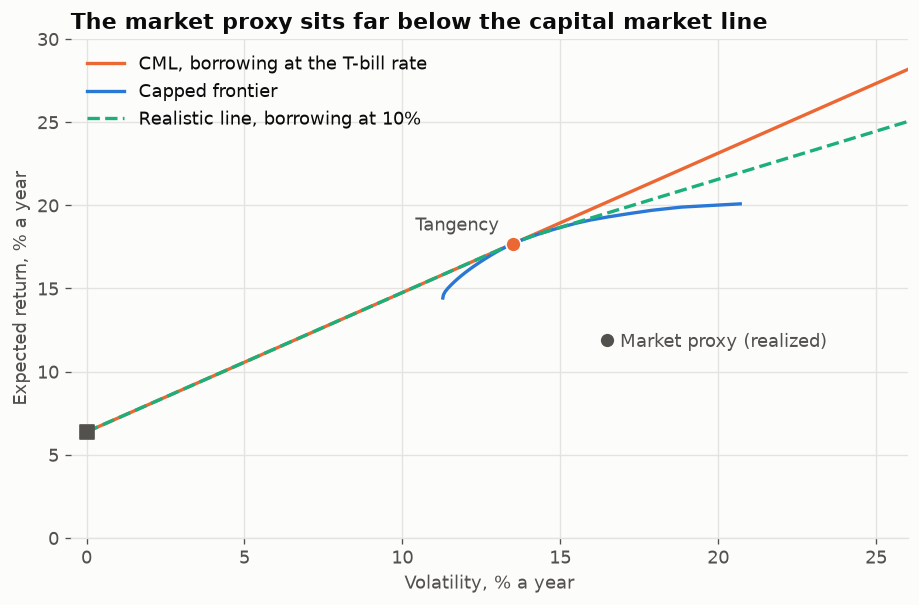

At the T-bill rate: Sharpe 0.84, return 17.7%, vol 13.5%
At a 10% rate: Sharpe 0.58, return 18.4%, vol 14.6%
CML return at market volatility: 20.2%, against 11.9% realized


In [3]:
rule = RULES["Capped"]
capped_summary, _ = fr.efficient_frontier(prac_mean, prac_cov, rule, points=30)
lend_weights = fr.solve_max_sharpe(prac_mean, prac_cov, RISK_FREE, rule)
borrow_weights = fr.solve_max_sharpe(prac_mean, prac_cov, BORROW_RATE, rule)
lend_return, lend_vol = fr.portfolio_stats(lend_weights, prac_mean, prac_cov)
borrow_return, borrow_vol = fr.portfolio_stats(borrow_weights, prac_mean, prac_cov)
lend_sharpe = (lend_return - RISK_FREE) / lend_vol
borrow_sharpe = (borrow_return - BORROW_RATE) / borrow_vol

volatility = np.linspace(0, 26, 53)
middle = capped_summary[capped_summary["volatility"].between(lend_vol, borrow_vol)]
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.grid(axis="x")
ax.plot(volatility, fr.capital_market_line(RISK_FREE, lend_sharpe, volatility / 100) * 100,
        color=SERIES_2, label="CML, borrowing at the T-bill rate")
ax.plot(capped_summary["volatility"] * 100, capped_summary["expected_return"] * 100,
        color=SERIES_1, label="Capped frontier")
beyond = np.linspace(borrow_vol, 0.26, 20)
path_x = np.r_[0, lend_vol, middle["volatility"], borrow_vol, beyond]
path_y = np.r_[RISK_FREE, lend_return, middle["expected_return"], borrow_return,
               fr.capital_market_line(BORROW_RATE, borrow_sharpe, beyond)]
ax.plot(path_x * 100, path_y * 100, color=SERIES_3, linestyle="--",
        label="Realistic line, borrowing at 10%")
ax.scatter(lend_vol * 100, lend_return * 100, s=80, color=SERIES_2, edgecolor=SURFACE, zorder=5)
ax.annotate("Tangency", (lend_vol * 100, lend_return * 100), xytext=(-8, 8),
            textcoords="offset points", ha="right", color=MUTED)
ax.scatter(market_vol * 100, market_return * 100, s=80, color=MUTED, edgecolor=SURFACE, zorder=5)
ax.annotate("Market proxy (realized)", (market_vol * 100, market_return * 100), xytext=(8, -4),
            textcoords="offset points", color=MUTED)
ax.scatter(0, RISK_FREE * 100, s=80, marker="s", color=MUTED, zorder=5)
ax.set_xlim(-0.5, 26)
ax.set_ylim(0, 30)
ax.set_xlabel("Volatility, % a year")
ax.set_ylabel("Expected return, % a year")
ax.set_title("The market proxy sits far below the capital market line")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "05_capital_market_line.png")
plt.show()

print(f"At the T-bill rate: Sharpe {lend_sharpe:.2f}, return {lend_return:.1%}, vol {lend_vol:.1%}")
print(f"At a 10% rate: Sharpe {borrow_sharpe:.2f}, return {borrow_return:.1%}, vol {borrow_vol:.1%}")
print(f"CML return at market volatility: "
      f"{fr.capital_market_line(RISK_FREE, lend_sharpe, market_vol):.1%}, "
      f"against {market_return:.1%} realized")

## 3. Is the Nifty the market portfolio?

CAPM says the market should sit on the CML. It appears far below it. There are four possible
explanations, and they are hard to separate:

1. **Estimation error:** the tangency portfolio is overfitted to the sample.
2. **Survivorship:** our 25 stocks are winners, while the index held everything at the time.
3. **Proxy problems:** the NIFTYBEES series misses some early dividends.
4. **The theory:** the market may really be inefficient.

Roll's critique adds a deeper limit. The true market portfolio includes every asset, such as bonds,
property and human capital, so CAPM can't be properly tested with any stock index.

### Measuring the survivorship gap

We can measure part of this directly. Build the long-only mix of our 25 stocks that tracks the
Nifty most closely. If it moves with the index almost perfectly but earns far more, that gap can't be
explained by different risk exposure.

In [4]:
tracker = fr.tracking_portfolio(excess[market], excess[stocks])
tracked = excess[stocks] @ tracker
gap = (tracked - excess[market]) * 12
fit = np.corrcoef(tracked, excess[market])[0, 1] ** 2
years = len(excess) / 12
print(f"R² with market: {fit:.3f}; tracking error {gap.std() / np.sqrt(12):.1%}")
print(f"Tracker return minus market: {gap.mean():.1%} a year "
      f"(standard error {gap.std() / np.sqrt(len(excess)):.1%})")
print(f"Sharpe: tracker {tracked.mean() / tracked.std() * np.sqrt(12):.2f}, market {market_sharpe:.2f}")
print(f"Effective stocks: {fr.effective_stocks(tracker):.1f}")
tracker.sort_values(ascending=False).head(8).round(3).to_frame("tracking_weight")

R² with market: 0.974; tracking error 2.7%
Tracker return minus market: 6.3% a year (standard error 0.7%)
Sharpe: tracker 0.73, market 0.33
Effective stocks: 17.1


,tracking_weight
HDFCBANK,0.133
INFY,0.092
RELIANCE,0.072
SBIN,0.067
ICICIBANK,0.060
HCLTECH,0.049
ITC,0.045
LT,0.045


Fit in-sample, the tracker follows the index closely yet earned far more. It's the same risk with
a much higher return, which is what you'd expect if today's index members were selected for past
success, with missing dividends adding a little. **So history overstates this universe's return by
several points a year**, and the optimizer's Sharpe ratios inherit that bias.

This closes much of the apparent gap to the CML. Measured on the same survivor stocks, a market-like
portfolio has a Sharpe ratio not far below the capped tangency portfolio's. The fit is in-sample, so
treat the size of the gap as approximate.

### How far is the tangency portfolio from the market?

Active share is the part of a portfolio that differs from a benchmark: 0% is identical, 100% shares
nothing.

In [5]:
def active_share(a, b):
    return (a - b).abs().sum() / 2


capped = tangency["Practical", "Capped"]
compare = pd.DataFrame({"tangency": capped, "market_tracker": tracker})
compare["difference"] = compare["tangency"] - compare["market_tracker"]
sectors = data.universe.set_index("symbol")["sector"]
by_sector = compare.groupby(sectors).sum().sort_values("difference")

mid = fr.frontier_point(prac_mean, prac_cov, rule, 0.5)
print(f"Active share of capped tangency against tracker: {active_share(capped, tracker):.0%}")
print(f"Active share of capped tangency against Stage 4 candidate: {active_share(capped, mid):.0%}")
by_sector.round(3)

Active share of capped tangency against tracker: 63%
Active share of capped tangency against Stage 4 candidate: 6%


,tangency,market_tracker,difference
sector,,,
Financial Services,0.141,0.306,-0.166
Energy,0.000,0.095,-0.095
Automobile,0.000,0.076,-0.076
Construction,0.000,0.045,-0.045
Telecom,0.000,0.039,-0.039
Metals,0.000,0.035,-0.035
Power,0.000,0.025,-0.025
Cement,0.036,0.029,0.007
Information Technology,0.238,0.177,0.061


The tangency portfolio is a strong sector bet against the market, away from financials and into
defensive sectors. So the portfolio theory calls "the market" looks very different from the actual
market. Any investor holding it is making a large active bet, whatever the theory says.

## 4. How much does the risk-free rate matter?

Stage 1 said we would test this. The rate moved between 2.8% and 10.5% during the sample.

In [6]:
base = fr.solve_max_sharpe(prac_mean, prac_cov, RISK_FREE, rule)
rows = {}
for rate in [0.04, 0.05, RISK_FREE, 0.08, 0.10]:
    weights = fr.solve_max_sharpe(prac_mean, prac_cov, rate, rule)
    expected, volatility = fr.portfolio_stats(weights, prac_mean, prac_cov)
    rows[f"{rate:.1%}"] = {"expected_return": expected, "volatility": volatility,
                           "sharpe": (expected - rate) / volatility,
                           "active_share_vs_base": active_share(weights, base)}
pd.DataFrame(rows).T.round(3)

,expected_return,volatility,sharpe,active_share_vs_base
4.0%,0.173,0.131,1.017,0.049
5.0%,0.175,0.132,0.941,0.031
6.4%,0.177,0.135,0.838,0.000
8.0%,0.180,0.139,0.719,0.045
10.0%,0.184,0.146,0.578,0.128


The Sharpe ratio changes with the rate, but the portfolio itself barely moves. Getting the
rate slightly wrong does little harm when caps are in place.

### When the tangency portfolio breaks

With shorts allowed, a tangency portfolio exists only if the GMV return is above the risk-free rate.
As the two approach each other, weights shoot toward infinity, and past that point no maximum Sharpe
exists at all. The engine now refuses this case. In the test below, the strategy falls back to the
GMV portfolio whenever it occurs, and the count shows how often that was.

## 5. Do tangency portfolios deliver their promised Sharpe ratio?

This uses the same walk-forward test as Stage 4, plus each portfolio's promised Sharpe at each
rebalance. Trading costs are excluded, and the holdout remains untouched.

In [7]:
fallbacks = {}


def tangency_strategy(label, inputs, limits):
    def build(train):
        rate = window_rate(train)
        mean, cov = fr.annualize(*inputs(train), rate)
        try:
            return fr.solve_max_sharpe(mean, cov, rate, limits)
        except ValueError:
            fallbacks[label, len(train)] = fallbacks.get((label, len(train)), 0) + 1
            return fr.solve_min_variance(mean, cov, None, limits)
    return build


def candidate_strategy(train):
    mean, cov = fr.annualize(*practical(train), RISK_FREE)
    return fr.frontier_point(mean, cov, RULES["Capped"], 0.5)


strategies = {f"{label} tangency, {name}": tangency_strategy(f"{label}, {name}", fn, limits)
              for label, fn in [("Textbook", textbook), ("Practical", practical)]
              for name, limits in RULES.items()}
strategies["Stage 4 candidate"] = candidate_strategy
strategies["Equal weight"] = lambda train: pd.Series(1 / len(stocks), index=stocks)
strategies["Market proxy"] = lambda train: pd.Series({market: 1.0})

long_window = backtest.run(excess, strategies, window=60, step=12)
short_window = backtest.run(excess, strategies, window=36, step=12)
card_60 = backtest.scorecard(long_window)
card_36 = backtest.scorecard(short_window)
print(f"Rebalances with no tangency portfolio, by inputs and window length: {fallbacks}")
card_60.sort_values("sharpe", ascending=False).round(3)

Rebalances with no tangency portfolio, by inputs and window length: {('Textbook, Shorts allowed', 36): 3}


,excess_return,volatility,sharpe,max_drawdown,turnover,largest_position,short_exposure
Equal weight,0.147,0.162,0.907,-0.254,0.000,0.040,0.000
Stage 4 candidate,0.134,0.151,0.884,-0.164,0.142,0.100,0.000
"Practical tangency, Capped",0.139,0.161,0.865,-0.186,0.147,0.100,0.000
"Textbook tangency, Capped",0.141,0.164,0.857,-0.188,0.184,0.100,0.000
"Practical tangency, Long-only",0.162,0.218,0.744,-0.283,0.303,0.291,0.000
"Textbook tangency, Long-only",0.187,0.252,0.743,-0.346,0.465,0.394,0.000
Market proxy,0.093,0.169,0.552,-0.313,0.000,1.000,0.000
"Practical tangency, Shorts allowed",0.194,0.406,0.477,-0.573,1.086,0.436,1.318
"Textbook tangency, Shorts allowed",0.352,0.975,0.361,-1.575,5.073,0.987,4.298


In [8]:
for name in ["Textbook tangency, Shorts allowed", "Practical tangency, Shorts allowed"]:
    largest = short_window.weights[name].abs().max(axis=1).max()
    print(f"{name}, 36-month window: largest position {largest:.1f} times capital")
card_36.sort_values("sharpe", ascending=False).round(3)

Textbook tangency, Shorts allowed, 36-month window: largest position 3.3 times capital
Practical tangency, Shorts allowed, 36-month window: largest position 1.5 times capital


,excess_return,volatility,sharpe,max_drawdown,turnover,largest_position,short_exposure
Equal weight,0.141,0.156,0.904,-0.254,0.000,0.040,0.000
"Textbook tangency, Long-only",0.163,0.182,0.896,-0.175,0.476,0.339,0.000
"Textbook tangency, Capped",0.133,0.151,0.882,-0.166,0.296,0.100,0.000
"Practical tangency, Capped",0.135,0.154,0.876,-0.180,0.256,0.100,0.000
Stage 4 candidate,0.125,0.145,0.863,-0.168,0.238,0.100,0.000
"Practical tangency, Long-only",0.144,0.172,0.841,-0.161,0.420,0.267,0.000
"Practical tangency, Shorts allowed",0.250,0.422,0.591,-0.519,2.064,0.617,1.788
Market proxy,0.081,0.161,0.505,-0.313,0.000,1.000,0.000
"Textbook tangency, Shorts allowed",-0.126,0.546,-0.231,-0.984,5.452,0.978,4.047


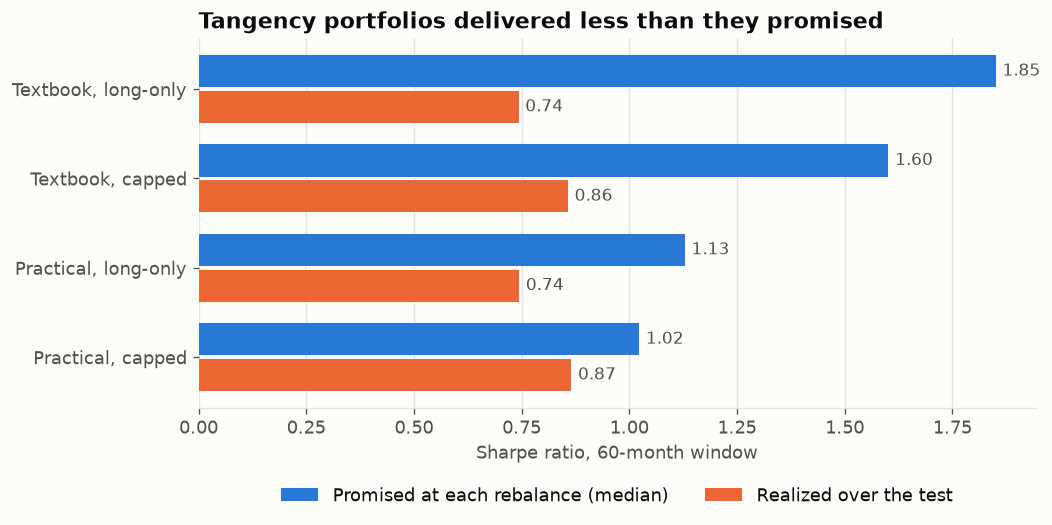

,promised_sharpe,realized_sharpe,delivered
portfolio,,,
"Textbook tangency, Long-only",1.85,0.74,0.40
"Textbook tangency, Capped",1.60,0.86,0.54
"Practical tangency, Long-only",1.13,0.74,0.66
"Practical tangency, Capped",1.02,0.87,0.85


In [9]:
def promised(strategy_inputs, result, name, window):
    values = []
    for date, weights in result.weights[name].iterrows():
        train = excess.loc[:date].iloc[-window - 1:-1]
        rate = window_rate(train)
        mean, cov = fr.annualize(*strategy_inputs(train), rate)
        values.append(fr.sharpe_ratio(weights, mean, cov, rate))
    return float(np.median(values))


rows = []
for name, fn in [("Textbook tangency, Long-only", textbook), ("Textbook tangency, Capped", textbook),
                 ("Practical tangency, Long-only", practical), ("Practical tangency, Capped", practical)]:
    rows.append({"portfolio": name, "promised_sharpe": promised(fn, long_window, name, 60),
                 "realized_sharpe": card_60.loc[name, "sharpe"]})
delivery = pd.DataFrame(rows).set_index("portfolio")
delivery["delivered"] = delivery["realized_sharpe"] / delivery["promised_sharpe"]

labels = ["Textbook, long-only", "Textbook, capped", "Practical, long-only", "Practical, capped"]
positions = np.arange(len(delivery))
fig, ax = plt.subplots(figsize=(9, 4))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
bars_a = ax.barh(positions - 0.2, delivery["promised_sharpe"], height=0.36, color=SERIES_1,
                 label="Promised at each rebalance (median)")
bars_b = ax.barh(positions + 0.2, delivery["realized_sharpe"], height=0.36, color=SERIES_2,
                 label="Realized over the test")
ax.bar_label(bars_a, fmt="%.2f", padding=4, color=MUTED, fontsize=10)
ax.bar_label(bars_b, fmt="%.2f", padding=4, color=MUTED, fontsize=10)
ax.set_yticks(positions, labels)
ax.invert_yaxis()
ax.set_xlabel("Sharpe ratio, 60-month window")
ax.set_title("Tangency portfolios delivered less than they promised")
ax.legend(frameon=False, ncols=2, loc="upper center", bbox_to_anchor=(0.5, -0.17))
fig.savefig(FIGURES / "05_promised_sharpe.png")
plt.show()
delivery.round(2)

## Stage 5 conclusions

1. **The math works:** closed-form and rescaled numerical tangency portfolios agree.
2. **Promises were overstated, but less so with practical inputs:** textbook tangency portfolios
   delivered about half their promised Sharpe ratio or less, and capped practical ones most of it.
3. **The market sits below the estimated CML,** but this is weak evidence against market efficiency.
   Overfitting, survivorship and a flawed proxy all push the same way, and Roll's critique limits any
   such test.
4. **Survivorship is large:** a 25-stock mix tracking the Nifty beat it by several points a year.
5. **Unconstrained tangency is unusable:** it needs extreme positions, lost everything in the test,
   and sometimes doesn't exist at all.
6. **Capped tangency is robust:** its results hold across windows, and the risk-free rate changes it
   little.
7. **Nothing beat equal weight clearly:** the capped portfolios stayed close to it on Sharpe ratio,
   with smaller drawdowns. Stage 10 has to settle this, after costs and on the holdout.

### Decision for Stage 6

The **capped tangency portfolio on practical inputs** becomes the risky fund. It's very close to the
Stage 4 candidate and performs about the same, and it is what separation theory calls for. Stage 6
then decides how much of it each type of investor should hold, alongside T-bills.